# Lab 3-07：用 LlamaIndex 把整條 RAG 重組一次

**目標**：前幾本是「一個零件一個套件」拼起來的（LlamaIndex 切塊、Chroma、rank_bm25、sentence-transformers）。這一本改用 LlamaIndex 的高階元件把同一條管線組起來，用同一份題庫對照結果與程式量。

**你會學到**
- LlamaIndex 的四個核心物件：`Document` → `Node` → `VectorStoreIndex` → `QueryEngine`
- 它內建的「metadata 跟著 embed」就是 contextual chunking
- 擴充點：自訂 `BaseRetriever` 接 BM25、`QueryFusionRetriever` 做 RRF、`SentenceTransformerRerank` 做重排
- 什麼時候用框架、什麼時候自己拼

**前置**：Lab 3-04、3-05、3-06。原理見 `00_concepts.md` 第 7 節。

**對應投影片**：「選型：RAG 框架」「Lab 3 檢索到組裝」

![零件拼裝 對照 LlamaIndex](images/llamaindex_parts.jpg)

*圖：上面一列是我們前幾本用的零件，下面一列是 LlamaIndex 的對應元件，虛線連起來的兩格做同一件事。朱紅框是 LlamaIndex 沒有內建、要自己接上去的部分：BM25 和 RRF 用自訂 Retriever 掛進去。*

## Step 1：設定模型

LlamaIndex 用全域的 `Settings` 指定 embedding 模型與 LLM。兩個都接本地 Ollama：
- `OllamaEmbedding`：走 Ollama 原生 API。
- `OpenAILike`：走 Ollama 的 OpenAI 相容 API；`is_chat_model=True` 才會用 chat 格式。

In [1]:
from llama_index.core import Settings
from llama_index.embeddings.ollama import OllamaEmbedding
from llama_index.llms.openai_like import OpenAILike

Settings.embed_model = OllamaEmbedding(model_name="bge-m3", base_url="http://localhost:11434")
Settings.llm = OpenAILike(api_base="http://localhost:11434/v1", api_key="ollama", model="qwen2.5:3b",
                          is_chat_model=True, temperature=0, timeout=180)

print(len(Settings.embed_model.get_text_embedding("測試")), "維")

1024 維


## Step 2：`Document`——文字加 metadata

把文件標題、服務、狀態放進 metadata。重點是 `excluded_embed_metadata_keys`：哪些 metadata **不要**跟著文字一起 embed。
標題要（讓每塊都有主詞），狀態不要（「archived」這個字不該影響語意）。

In [2]:
from llama_index.core import Document

from rag_utils import load_docs, load_qa

docs = load_docs()
qa = load_qa()
li_docs = [
    Document(
        text=d.text,
        id_=d.doc_id,
        metadata={"title": d.title, "service": d.meta.get("service", ""), "status": d.meta["status"]},
        excluded_embed_metadata_keys=["service", "status"],
        excluded_llm_metadata_keys=["status"],
    )
    for d in docs
]
print(li_docs[0].metadata)

{'title': 'anchor-order 訂單服務說明（v6 舊版，已封存）', 'service': 'anchor-order', 'status': 'archived'}


## Step 3：切成 `Node`，看看「實際被 embed 的文字」

明確指定 `MarkdownNodeParser`。LlamaIndex 預設用 `SentenceSplitter`，但它會依標題切不了，且需要額外下載 NLTK 資料。
`get_content(MetadataMode.EMBED)` 印出送進 embedding 模型的文字：標題自動接在前面——這就是 Lab 3-03 的 contextual chunking，框架幫你做了。

In [3]:
from llama_index.core.node_parser import MarkdownNodeParser
from llama_index.core.schema import MetadataMode

nodes = MarkdownNodeParser().get_nodes_from_documents(li_docs)
nodes = [n for n in nodes if n.text.startswith("## ")]  # 跳過每份文件開頭的標題＋metadata 行
print(len(nodes), "個 node")
print(nodes[10].get_content(metadata_mode=MetadataMode.EMBED))

113 個 node
title: hfctl 常用指令速查
header_path: /hfctl 常用指令速查/

## 唯讀（任何人可用）

| 指令 | 用途 |
|---|---|
| `hfctl tidepay acquirer-status` | 看兩家收單行的健康度 |
| `hfctl tidepay stats --code <錯誤碼> --group-by bin --last 1h` | 依卡號前 6 碼統計錯誤 |
| `hfctl mq lag --top 5` | 消費落後最多的 5 個 consumer group |
| `hfctl auth key-history` | 金鑰輪換紀錄 |


## Step 4：`VectorStoreIndex`——一行建索引

預設存在記憶體（`SimpleVectorStore`）。要換成 Chroma、Qdrant 等，只要裝對應的整合套件並傳 `storage_context`，其餘程式不變。

In [4]:
from llama_index.core import VectorStoreIndex

index = VectorStoreIndex(nodes, show_progress=False)
print("索引完成，向量數：", len(index.vector_store.data.embedding_dict))

索引完成，向量數： 113


## Step 5：`QueryEngine`——一行問答

`as_query_engine` 把「檢索 → 組 prompt → 呼叫 LLM」包在一起。`filters` 對應 Chroma 的 `where`。
回傳物件除了答案，還有 `source_nodes`：檢索到哪幾塊、分數多少。

In [5]:
from llama_index.core.vector_stores import ExactMatchFilter, MetadataFilters

current_only = MetadataFilters(filters=[ExactMatchFilter(key="status", value="current")])
engine = index.as_query_engine(similarity_top_k=3, filters=current_only)

resp = engine.query("breakwater 的限流是每分鐘幾次？")
print(resp.response)
for sn in resp.source_nodes:
    print(f"  {sn.score:.3f}  {sn.node.ref_doc_id}  {sn.node.text[:30]!r}")

breakwater 的限流規則是，一般 API 金鑰每分鐘允許 600 次請求。
  0.752  svc-breakwater  '## 限流規則\n\n- 一般 API 金鑰：每分鐘 600 次'
  0.676  svc-breakwater  '## 逾時與熔斷\n\n- 轉發到上游的預設逾時是 15 秒，設'
  0.619  svc-breakwater  '## JWKS 快取\n\nbreakwater 會驗證 lig'


點一下內部：LlamaIndex 實際送給 LLM 的 prompt 長這樣。中文問題配英文指令，3B 模型有時會用英文回答，可以換成自己的 prompt。

In [6]:
prompts = engine.get_prompts()
print(prompts["response_synthesizer:text_qa_template"].get_template()[:400])

Context information is below.
---------------------
{context_str}
---------------------
Given the context information and not prior knowledge, answer the query.
Query: {query_str}
Answer: 


In [7]:
from llama_index.core import PromptTemplate

QA_TEMPLATE = PromptTemplate(
    "你是海風科技的內部技術助理。只能根據下面的參考資料回答，沒有就說「資料中沒有這個資訊」。回答要簡短。\n"
    "參考資料：\n{context_str}\n\n問題：{query_str}\n回答："
)
engine.update_prompts({"response_synthesizer:text_qa_template": QA_TEMPLATE})
print(engine.query("TP-4021 可以重試嗎？").response)

不可以，處理方式為呼叫端程式錯誤，不可重試，要查呼叫端。


## Step 6：用同一份題庫評估 LlamaIndex 的向量檢索

`as_retriever` 只做檢索不做生成。`node.ref_doc_id` 就是原始文件 id，可以直接算 Hit@k。

In [8]:
import numpy as np

from rag_utils import dedup_docs, hit_at_k, reciprocal_rank


def evaluate(retrieve) -> dict:
    hit1, hit3, rr = [], [], []
    for q in qa:
        ranked = dedup_docs([f"{d}#" for d in retrieve(q["question"])])
        hit1.append(hit_at_k(ranked, q["doc_ids"], 1))
        hit3.append(hit_at_k(ranked, q["doc_ids"], 3))
        rr.append(reciprocal_rank(ranked, q["doc_ids"]))
    return {"Hit@1": np.mean(hit1), "Hit@3": np.mean(hit3), "MRR": np.mean(rr)}


vector_retriever = index.as_retriever(similarity_top_k=20, filters=current_only)
li_results = {"LlamaIndex 向量": evaluate(lambda s: [n.node.ref_doc_id for n in vector_retriever.retrieve(s)])}
print(li_results)

{'LlamaIndex 向量': {'Hit@1': np.float64(0.8947368421052632), 'Hit@3': np.float64(1.0), 'MRR': np.float64(0.9473684210526315)}}


## Step 7：擴充點一——自訂 Retriever 接 BM25

LlamaIndex 有 BM25 整合套件，但這裡不另外安裝：繼承 `BaseRetriever`、實作 `_retrieve`，就能把 Lab 3-04 的 `rank_bm25` 接進來。
斷詞用的文字跟 embedding 一樣（標題＋內文）。

In [9]:
from llama_index.core.retrievers import BaseRetriever
from llama_index.core.schema import NodeWithScore
from rank_bm25 import BM25Okapi

from rag_utils import tokenize


class BM25Retriever(BaseRetriever):
    def __init__(self, nodes, k: int = 20):
        self.nodes = [n for n in nodes if n.metadata["status"] == "current"]
        self.bm25 = BM25Okapi([tokenize(n.get_content(metadata_mode=MetadataMode.EMBED)) for n in self.nodes])
        self.k = k
        super().__init__()

    def _retrieve(self, query_bundle):
        scores = self.bm25.get_scores(tokenize(query_bundle.query_str))
        top = np.argsort(-scores)[:self.k]
        return [NodeWithScore(node=self.nodes[i], score=float(scores[i])) for i in top]


bm25_retriever = BM25Retriever(nodes)
for n in bm25_retriever.retrieve("BW-504 是什麼？")[:3]:
    print(f"{n.score:6.2f}  {n.node.ref_doc_id}")

  4.16  svc-breakwater
  3.76  svc-sandbar-dw
  3.72  svc-reef-search


## Step 8：擴充點二——`QueryFusionRetriever` 做 RRF

跟 Lab 3-04 Step 9 一樣，只是這次兩路都是 LlamaIndex 的 retriever。`num_queries=1` 表示不做查詢改寫；改成 4 就會讓 LLM 多產生 3 個改寫查詢（Lab 3-05 的 multi-query）。

In [10]:
from llama_index.core.retrievers import QueryFusionRetriever

fusion = QueryFusionRetriever(
    [vector_retriever, bm25_retriever],
    mode="reciprocal_rerank", num_queries=1, similarity_top_k=20, use_async=False,
)
li_results["LlamaIndex 混合"] = evaluate(lambda s: [n.node.ref_doc_id for n in fusion.retrieve(s)])
print(li_results["LlamaIndex 混合"])

{'Hit@1': np.float64(0.9210526315789473), 'Hit@3': np.float64(0.9736842105263158), 'MRR': np.float64(0.9539473684210527)}


## Step 9：擴充點三——`SentenceTransformerRerank` 重排

重排在 LlamaIndex 叫 node postprocessor：拿到檢索結果後再處理一次。用 Lab 3-05 同一個 cross-encoder。

In [11]:
from llama_index.core.postprocessor import SentenceTransformerRerank

rerank = SentenceTransformerRerank(model="cross-encoder/mmarco-mMiniLMv2-L12-H384-v1", top_n=10)


def fusion_rerank(s: str) -> list[str]:
    nodes_ = rerank.postprocess_nodes(fusion.retrieve(s), query_str=s)
    return [n.node.ref_doc_id for n in nodes_]


li_results["LlamaIndex 混合＋重排"] = evaluate(fusion_rerank)
print(li_results["LlamaIndex 混合＋重排"])

{'Hit@1': np.float64(0.9736842105263158), 'Hit@3': np.float64(1.0), 'MRR': np.float64(0.9868421052631579)}


## Step 10：組成完整的 query engine

`RetrieverQueryEngine` 接受任何 retriever 和一串 postprocessor。這就是 Lab 3-06「最佳組合」的 LlamaIndex 版。

In [12]:
from llama_index.core.query_engine import RetrieverQueryEngine

best_engine = RetrieverQueryEngine.from_args(
    fusion,
    node_postprocessors=[SentenceTransformerRerank(model="cross-encoder/mmarco-mMiniLMv2-L12-H384-v1", top_n=3)],
    text_qa_template=QA_TEMPLATE,
)
for q in ["BW-504 是什麼？", "使用者付款時一直被扣兩次錢，以前發生過嗎？原因是什麼？"]:
    r = best_engine.query(q)
    print("問：", q)
    print("答：", r.response.strip())
    print("   來源：", [sn.node.ref_doc_id for sn in r.source_nodes])

問： BW-504 是什麼？
答： BW-504 是上游逾時。
   來源： ['svc-breakwater', 'rb-bw-503-circuit', 'rb-bw-503-circuit']
問： 使用者付款時一直被扣兩次錢，以前發生過嗎？原因是什麼？
答： 資料中沒有這個資訊。
   來源： ['pm-2026-0314-double-charge', 'pm-2026-0314-double-charge', 'pm-2026-0314-double-charge']


來源和回答要分開看：來源全對時，3B 模型仍可能回「資料中沒有這個資訊」——這就是 Lab 3-06 說的「生成的錯」，框架不會幫你解決。

## Step 11：跟拼裝版對照

用 `rag_utils`（前幾本的零件）跑同樣三種設定，放在同一張圖。

In [13]:
from sentence_transformers import CrossEncoder

from rag_utils import BM25Index, build_collection, chunk_docs, rrf, vector_search

chunks = chunk_docs(docs)
text_of = {c.chunk_id: c.text for c in chunks}
col = build_collection(chunks, "compare")
bm25 = BM25Index(chunks)
allowed = {c.chunk_id for c in chunks if c.meta["status"] == "current"}
ce = CrossEncoder("cross-encoder/mmarco-mMiniLMv2-L12-H384-v1")
CURRENT = {"status": "current"}


def ours_hybrid(s):
    return rrf([bm25.search(s, 20, allowed), vector_search(col, s, 20, CURRENT)])[:20]


def ours_rerank(s):
    cands = ours_hybrid(s)
    return [cands[i] for i in np.argsort(-ce.predict([(s, text_of[c]) for c in cands]))]


ours = {
    "拼裝 向量": evaluate(lambda s: [c.split("#")[0] for c in vector_search(col, s, 20, CURRENT)]),
    "拼裝 混合": evaluate(lambda s: [c.split("#")[0] for c in ours_hybrid(s)]),
    "拼裝 混合＋重排": evaluate(lambda s: [c.split("#")[0] for c in ours_rerank(s)]),
}

       零件拼裝  LlamaIndex
向量     0.89        0.89
混合     0.92        0.92
混合＋重排  0.97        0.97


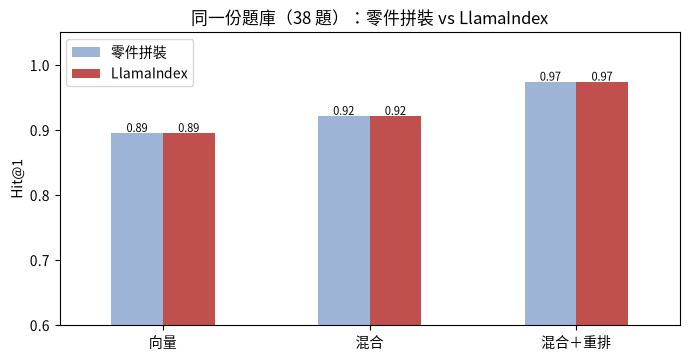

In [14]:
import matplotlib.pyplot as plt
import pandas as pd

from course_utils.viz import setup_cjk

setup_cjk()

table = pd.DataFrame({
    "向量": [ours["拼裝 向量"]["Hit@1"], li_results["LlamaIndex 向量"]["Hit@1"]],
    "混合": [ours["拼裝 混合"]["Hit@1"], li_results["LlamaIndex 混合"]["Hit@1"]],
    "混合＋重排": [ours["拼裝 混合＋重排"]["Hit@1"], li_results["LlamaIndex 混合＋重排"]["Hit@1"]],
}, index=["零件拼裝", "LlamaIndex"]).T
print(table.round(2))
ax = table.plot.bar(rot=0, figsize=(8, 3.8), color=["#9db4d6", "#c0504d"], ylim=(0.6, 1.05))
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
ax.set_ylabel("Hit@1")
ax.set_title(f"同一份題庫（{len(qa)} 題）：零件拼裝 vs LlamaIndex")
plt.show()

兩邊用的是同一個 embedding 模型、同一個切法、同一個 cross-encoder，所以分數幾乎一樣。細節上仍有差異（LlamaIndex 把標題寫成 `title: ...` 前綴、Chroma 用近似搜尋），換一份語料時不保證完全相同。

## Step 12：程式量對照

數一下兩邊的核心程式各幾行（不含註解與空行）。拼裝版取 `rag_utils.py` 裡用到的函式；LlamaIndex 版是把這一本 Step 1～10 濃縮成最小可跑的版本。

In [15]:
import inspect

import rag_utils

LLAMAINDEX_MINIMAL = """
Settings.embed_model = OllamaEmbedding(model_name="bge-m3", base_url=URL)
Settings.llm = OpenAILike(api_base=URL + "/v1", api_key="ollama", model="qwen2.5:3b", is_chat_model=True)
li_docs = [Document(text=d.text, id_=d.doc_id, metadata={"title": d.title, "status": d.meta["status"]},
                    excluded_embed_metadata_keys=["status"]) for d in docs]
nodes = [n for n in MarkdownNodeParser().get_nodes_from_documents(li_docs) if n.text.startswith("## ")]
index = VectorStoreIndex(nodes)
current_only = MetadataFilters(filters=[ExactMatchFilter(key="status", value="current")])
class BM25Retriever(BaseRetriever):
    def __init__(self, nodes, k=20):
        self.nodes = [n for n in nodes if n.metadata["status"] == "current"]
        self.bm25 = BM25Okapi([tokenize(n.get_content(metadata_mode=MetadataMode.EMBED)) for n in self.nodes])
        self.k = k
        super().__init__()
    def _retrieve(self, query_bundle):
        scores = self.bm25.get_scores(tokenize(query_bundle.query_str))
        return [NodeWithScore(node=self.nodes[i], score=float(scores[i])) for i in np.argsort(-scores)[:self.k]]
fusion = QueryFusionRetriever([index.as_retriever(similarity_top_k=20, filters=current_only), BM25Retriever(nodes)],
                              mode="reciprocal_rerank", num_queries=1, similarity_top_k=20, use_async=False)
engine = RetrieverQueryEngine.from_args(fusion, node_postprocessors=[SentenceTransformerRerank(model=CE, top_n=3)],
                                        text_qa_template=QA_TEMPLATE)
"""


def count_lines(src: str) -> int:
    return sum(1 for l in src.splitlines() if l.strip() and not l.strip().startswith(("#", '"""')))


ours_lines = sum(count_lines(inspect.getsource(getattr(rag_utils, n))) for n in
                 ["chunk_docs", "build_collection", "vector_search", "tokenize", "BM25Index", "rrf"])
print(f"零件拼裝（rag_utils 裡的函式）：{ours_lines} 行，另外還要寫呼叫端的組 prompt、重排")
print(f"LlamaIndex（最小可跑版本）：  {count_lines(LLAMAINDEX_MINIMAL)} 行，已含 prompt 組裝與生成")

零件拼裝（rag_utils 裡的函式）：56 行，另外還要寫呼叫端的組 prompt、重排
LlamaIndex（最小可跑版本）：  20 行，已含 prompt 組裝與生成


怎麼選：

| | 零件拼裝 | LlamaIndex |
|---|---|---|
| 適合 | 要客製每一步、要除錯、要嵌進既有系統 | 快速做出可用版本、需要多種資料來源與向量庫 |
| 代價 | 自己維護膠水程式 | 抽象層多，預設值（英文 prompt、SentenceSplitter）要一一確認 |
| 本課立場 | 模組 5 把檢索包成 agent 的工具時，用拼裝版，因為每一步要看得見 | 選型時知道它能做什麼、擴充點在哪 |

## 試試看

1. 把 Step 8 的 `num_queries` 改成 3，讓 LLM 產生改寫查詢，重跑評估。花的時間和分數各變多少？
2. 把 Step 2 的 `excluded_embed_metadata_keys` 改成空清單（狀態也一起 embed），看 Hit@1 有沒有變。
3. 用 `index.as_chat_engine()` 連問兩題（「TP-5003 怎麼處理？」「那要誰核准？」），看第二題它有沒有接上前一題。

## 小結

- LlamaIndex 用 `Document → Node → Index → QueryEngine` 包住整條 RAG；metadata 跟著 embed 就是 contextual chunking。
- BM25、RRF、重排都靠擴充點接上：自訂 `BaseRetriever`、`QueryFusionRetriever`、node postprocessor；同一份題庫上分數與拼裝版相近。
- 模組 3 的主線到此結束。下一本 Lab 3-08 是選讀：當資料來源是 PDF，切塊之前的「解析」本身就會壞。